# Capstone Project Report: Earthquake Damage Prediction
**Author:** &emsp;&emsp;&emsp;&emsp;&emsp;&emsp;Arjun R (Data Science Intern)  
**GitHub Repository:** &nbsp;&nbsp;[View Source Code on GitHub](https://github.com/Arjunr3108/earthquake_damage_prediction)  
**Project Objective:** &emsp;&nbsp;Build an end-to-end machine learning pipeline to predict the ordinal **`damage_grade`** of buildings affected by the Gorkha earthquake (DrivenData competition dataset).


This project report is structured into the following key sections:
1. **Environment Setup & Libraries**
2. **Data Ingestion & Initial Structure Inspection**
3. **Exploratory Data Analysis (EDA)**
   - 3.1 Target Variable Analysis (Class Imbalance Check)
   - 3.2 Dataset Structure & Missing Value Audit
   - 3.3 Deep-Dive Exploratory Analysis: Regional & Structural Vulnerabilities
4. **Data Preparation & Stratified Splitting**
5. **Baseline Modeling & Preprocessing Pipeline Design**
6. **Hyperparameter Optimization via Optuna**
7. **Final Model Training & Feature Importance Interpretation**
8. **Actionable Insights for Seismologists and Urban Planners (Task 3)**
9. **Model Persistence & Inference Verification**
10. **Project Challenge & Technical Mitigation Report**

## 1. Environment Setup & Libraries
We begin by importing all necessary Python libraries required for data manipulation, visualization, preprocessing pipeline construction, machine learning modeling, evaluation metrics, and hyperparameter tuning.

In [1]:
# Load all necessary Python libraries and modules required for data preprocessing, pipeline building, and model evaluation.
from catboost import CatBoostClassifier
from IPython.display import display
from IPython.display import Markdown
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import TargetEncoder

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import optuna.visualization.matplotlib as optuna_plt
import pandas as pd
import seaborn as sns
import warnings

## 2. Data Ingestion & Initial Structure Inspection
To understand the dataset structure, we load the training features (`train_values.csv`) and the target labels (`train_labels.csv`), merging them using the unique identifier `building_id`. This creates a unified dataset for comprehensive exploratory analysis and training.

In [2]:
# Load the training datasets and preview their structures to verify data integrity and inspect the features/targets
train_values = pd.read_csv('train_values.csv')
train_labels = pd.read_csv('train_labels.csv')

display(Markdown("### Train Values (Features):"), train_values.head())
display(Markdown("### Train Label (Targets):"), train_labels.head())

### Train Values (Features):

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0


### Train Label (Targets):

,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


In [3]:
# Merge features and targets into a single dataset for joint analysis and model training
df = pd.merge(train_values, train_labels, on='building_id')

display(Markdown("### Preview of Merged DataFrame:"), df.head())

### Preview of Merged DataFrame:

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,3


## 3. Exploratory Data Analysis (EDA)
### 3.1 Target Variable Analysis (Class Imbalance Check)
Before training any predictive models, it is crucial to analyze the distribution of our target variable (`damage_grade`), which represents building damage levels:
* **1 (Minor Damage):** Low structural damage
* **2 (Moderate Damage):** Medium structural damage
* **3 (Severe Damage):** Almost complete destruction

We inspect both absolute counts and proportional percentages, followed by visual representations to check for class imbalance.

In [4]:
# Analyze the class distribution of the target variable to check for imbalance and guide model training strategy
class_counts = df['damage_grade'].value_counts()

display(Markdown("### Damage grade counts across classes:"), class_counts.rename_axis(None))

### Damage grade counts across classes:

,count
2,148259
3,87218
1,25124


In [5]:
# Convert class counts to percentages for a clearer view of proportional imbalance
class_percentages = df['damage_grade'].value_counts(normalize=True) * 100

display(Markdown("### Damage grade percentage across classes:"), class_percentages.rename_axis(None))

### Damage grade percentage across classes:

,proportion
2,56.891186
3,33.468022
1,9.640792


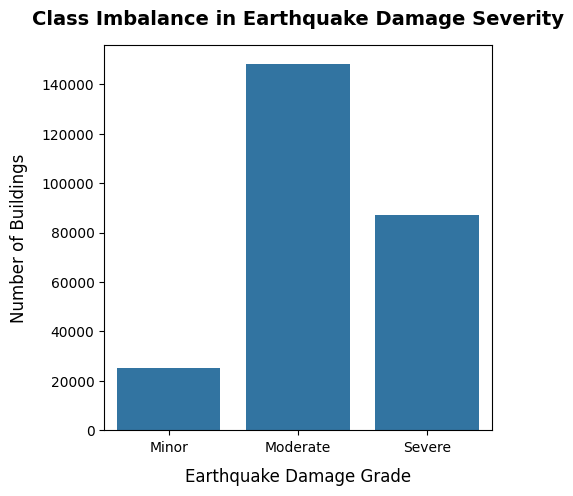

In [6]:
# Plot the frequency of each damage grade to visually inspect the degree of class imbalance
plt.figure(figsize=(5, 5))
sns.countplot(data=df, x='damage_grade')
plt.title('Class Imbalance in Earthquake Damage Severity', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Earthquake Damage Grade', fontsize=12, labelpad=10)
plt.ylabel('Number of Buildings', fontsize=12, labelpad=10)
plt.xticks(ticks=[0, 1, 2], labels=['Minor', 'Moderate', 'Severe'], rotation=0)
plt.show()

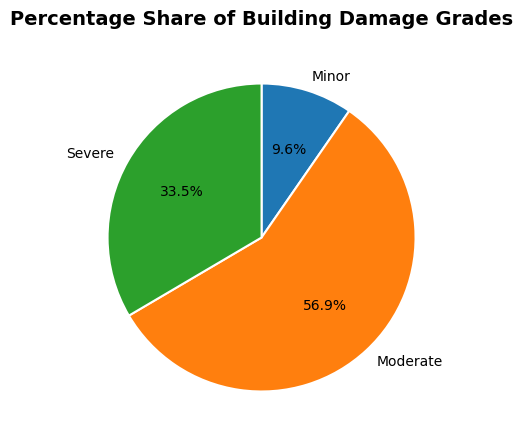

In [7]:
# Plot a pie chart to visualize the percentage distribution and relative share of each damage grade
plt.figure(figsize=(5, 5))
class_counts.sort_index().plot.pie(labels=['Minor', 'Moderate', 'Severe'], autopct='%1.1f%%', startangle=90, counterclock=False, wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
plt.title('Percentage Share of Building Damage Grades', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('')
plt.ylabel('')
plt.show()

### 3.2 Dataset Structure & Missing Value Audit
We audit data types, count the total number of numerical versus categorical features, and verify if any missing values exist to dictate our imputation or cleaning strategy.

In [8]:
# Check data types and missing values to determine encoding and imputation strategies
display(Markdown("### Dataset Info:"))
display(df.info())

### Dataset Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype 
---  ------                                  --------------   ----- 
 0   building_id                             260601 non-null  int64 
 1   geo_level_1_id                          260601 non-null  int64 
 2   geo_level_2_id                          260601 non-null  int64 
 3   geo_level_3_id                          260601 non-null  int64 
 4   count_floors_pre_eq                     260601 non-null  int64 
 5   age                                     260601 non-null  int64 
 6   area_percentage                         260601 non-null  int64 
 7   height_percentage                       260601 non-null  int64 
 8   land_surface_condition                  260601 non-null  object
 9   foundation_type                         260601 non-null  object
 10  roof_type                               260601 non-null 

None

In [9]:
# Count numerical and categorical features and verify that no column types were missed before encoding
num_cols = len(df.select_dtypes(include=['number']).columns)
cat_cols = len(df.select_dtypes(include=['object', 'string']).columns)
total_cols = len(df.columns)
accounted_cols = num_cols + cat_cols

display(Markdown(f"**Numerical Columns:** {num_cols}"))
display(Markdown(f"**Categorical Columns:** {cat_cols}"))
display(Markdown(f"**Total Columns vs Accounted Columns:** {total_cols}/{accounted_cols}"))

**Numerical Columns:** 32

**Categorical Columns:** 8

**Total Columns vs Accounted Columns:** 40/40

In [10]:
# Quantify and inspect missing values across all features to determine the appropriate imputation or cleaning strategy
missing_counts = df.isna().sum()
features_with_missing = (df.isna().sum() > 0).sum()

display(Markdown("### Check for Missing Values:"), missing_counts)
display(Markdown(f"**Number of features with missing values:** {features_with_missing}"))

### Check for Missing Values:

,0
building_id,0
geo_level_1_id,0
geo_level_2_id,0
geo_level_3_id,0
count_floors_pre_eq,0
age,0
area_percentage,0
height_percentage,0
land_surface_condition,0
foundation_type,0


**Number of features with missing values:** 0

### 3.3 Deep-Dive Exploratory Analysis: Regional & Structural Vulnerabilities
To extract early insights, we cross-tabulate damage grades against geographic indicators (`geo_level_1_id`), building age, and superstructure material types (e.g., adobe mud versus engineered reinforced concrete) to visualize structural resilience patterns.

In [11]:
# Compute a cross-tabulation of damage grades by geo_level_1_id to inspect regional vulnerability distribution
geo_damage_counts = pd.crosstab(df['geo_level_1_id'], df['damage_grade'])

display(Markdown("### Damage Grade Distribution by Region (Geo Level 1):"), geo_damage_counts)

### Damage Grade Distribution by Region (Geo Level 1):

damage_grade,1,2,3
geo_level_1_id,,,
0,337,3075,599
1,411,1985,305
2,85,610,236
3,245,4550,2745
4,521,11164,2883
5,446,2014,230
6,2108,16222,6051
7,1033,11273,6688
8,654,8513,9913


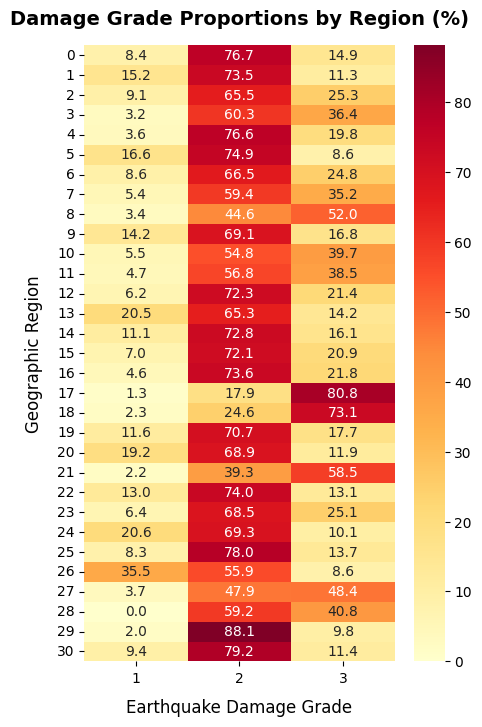

In [12]:
# Plot a heatmap of normalized proportions to visualize how damage grade distributions vary across geographic regions
geo_damage_proportions = (geo_damage_counts.div(geo_damage_counts.sum(axis=1), axis=0) * 100)

plt.figure(figsize=(5, 8))
sns.heatmap(geo_damage_proportions, annot=True, fmt='.1f', cmap='YlOrRd', cbar=True)
plt.title('Damage Grade Proportions by Region (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Earthquake Damage Grade', fontsize=12, labelpad=10)
plt.ylabel('Geographic Region', fontsize=12, labelpad=10)
plt.yticks(rotation=0)
plt.show()

In [13]:
# Cross-tabulate building age with damage grade to analyze how structural age relates to damage susceptibility
age_damage_counts = pd.crosstab(df['age'], df['damage_grade'])

display(Markdown("### Damage Grade Distribution by Building Age:"), age_damage_counts)

### Damage Grade Distribution by Building Age:

damage_grade,1,2,3
age,,,
0,7213,12721,6107
5,5590,19030,9077
10,4360,22370,12166
15,2878,20767,12365
20,1954,18603,11625
25,1131,14073,9162
30,640,10444,6944
35,352,6246,4112
40,283,6088,4188


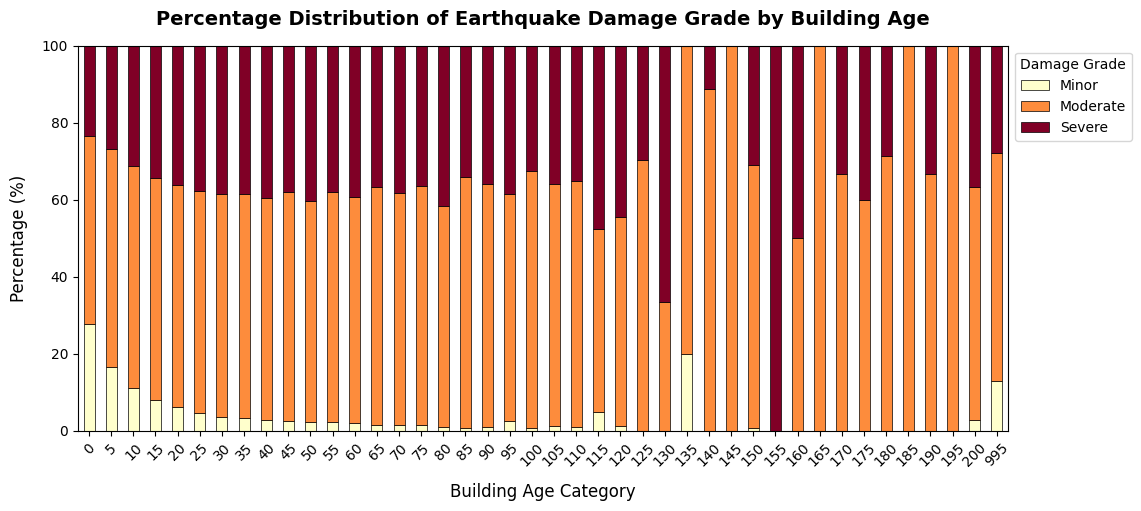

In [14]:
# Visualize how earthquake damage severity proportions shift across building age groups
age_damage_proportions = (age_damage_counts.div(age_damage_counts.sum(axis=1), axis=0) * 100)

fig, ax = plt.subplots(figsize=(12, 5))
age_damage_proportions.plot(kind='bar', stacked=True, ax=ax, colormap='YlOrRd', edgecolor='black', linewidth=0.5)
plt.title('Percentage Distribution of Earthquake Damage Grade by Building Age', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Building Age Category', fontsize=12, labelpad=10)
plt.ylabel('Percentage (%)', fontsize=12, labelpad=10)
plt.xticks(rotation=45)
plt.margins(y=0)
plt.legend(labels=['Minor', 'Moderate', 'Severe'], title='Damage Grade', bbox_to_anchor=(1, 1), loc='upper left', frameon=True)
plt.show()

In [15]:
# Cross-tabulate structural quality (adobe vs. RC) against damage grades to assess seismic resilience.
adobe_mud_damage_counts = pd.crosstab(df['has_superstructure_adobe_mud'], df['damage_grade'])
rc_engineered_damage_counts = pd.crosstab(df['has_superstructure_rc_engineered'], df['damage_grade'])

display(Markdown("### Damage Grade Distribution by Adobe Mud Superstructure:"), adobe_mud_damage_counts)
display(Markdown("### Damage Grade Distribution by Engineered RC Superstructure:"), rc_engineered_damage_counts)

### Damage Grade Distribution by Adobe Mud Superstructure:

damage_grade,1,2,3
has_superstructure_adobe_mud,,,
0,24530,134357,78613
1,594,13902,8605


### Damage Grade Distribution by Engineered RC Superstructure:

damage_grade,1,2,3
has_superstructure_rc_engineered,,,
0,22468,146857,87143
1,2656,1402,75


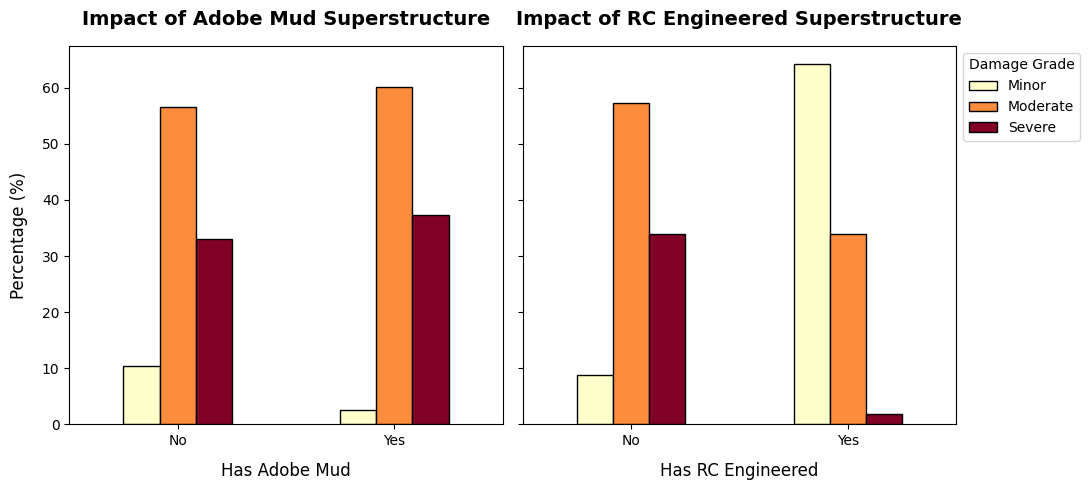

In [16]:
# Compare damage grade proportions between adobe mud and reinforced concrete (RC) structures.
adobe_mud_proportions = (adobe_mud_damage_counts.div(adobe_mud_damage_counts.sum(axis=1), axis=0) * 100)
rc_engineered_proportions = (rc_engineered_damage_counts.div(rc_engineered_damage_counts.sum(axis=1), axis=0) * 100)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

adobe_mud_proportions.plot(kind='bar', colormap='YlOrRd', edgecolor='black', ax=ax1)
ax1.set_title('Impact of Adobe Mud Superstructure', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Has Adobe Mud', fontsize=12, labelpad=10)
ax1.set_ylabel('Percentage (%)', fontsize=12, labelpad=10)
ax1.set_xticks(ticks=[0, 1], labels=['No', 'Yes'], rotation=0)

rc_engineered_proportions.plot(kind='bar', colormap='YlOrRd', edgecolor='black', ax=ax2)
ax2.set_title('Impact of RC Engineered Superstructure', fontsize=14, fontweight='bold', pad=15)
ax2.set_xlabel('Has RC Engineered', fontsize=12, labelpad=10)
ax2.set_ylabel('Percentage (%)', fontsize=12, labelpad=10)
ax2.set_xticks(ticks=[0, 1], labels=['No', 'Yes'], rotation=0)

ax1.get_legend().remove()
ax2.legend(labels=['Minor', 'Moderate', 'Severe'], title='Damage Grade', bbox_to_anchor=(1, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

## 4. Data Preparation & Stratified Splitting
To prepare the data for modeling, we isolate the target variable (`damage_grade`) from the feature matrix and safely preserve the `building_id` column for tracking.

To handle class distribution imbalances properly, we execute a **stratified train-test split**, ensuring that the ratio of each damage grade remains identical across both training and validation sets.

In [17]:
# Separate target variable and feature matrix for model training
target = df['damage_grade'].copy()
features = df.drop(columns=['damage_grade'])

display(Markdown("### Target Variable Preview (`damage_grade`):"), target.head())
display(Markdown("### Feature Matrix Preview:"), features.head())

### Target Variable Preview (`damage_grade`):

,damage_grade
0,3
1,2
2,3
3,2
4,3


### Feature Matrix Preview:

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0


In [18]:
# Preserve building IDs for future evaluation/submission before removing them from the feature set
building_ids = features['building_id'].copy()
features = features.drop(columns=['building_id'])

display(Markdown("### Building IDs Preview:"), building_ids.head())
display(Markdown("### Feature Matrix Preview (IDs Removed):"), features.head())

### Building IDs Preview:

,building_id
0,802906
1,28830
2,94947
3,590882
4,201944


### Feature Matrix Preview (IDs Removed):

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,6,487,12198,2,30,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
1,8,900,2812,2,10,8,7,o,r,n,...,0,0,0,0,0,0,0,0,0,0
2,21,363,8973,2,10,5,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
3,22,418,10694,2,10,6,5,t,r,n,...,0,0,0,0,0,0,0,0,0,0
4,11,131,1488,3,30,8,9,t,r,n,...,0,0,0,0,0,0,0,0,0,0


In [19]:
# Perform a stratified train-test split to preserve class proportions, then verify the distribution across sets
X_train, X_val, y_train, y_val = train_test_split(features, target, test_size=0.2, stratify=target, random_state=42)
target_percentages = target.value_counts(normalize=True) * 100
y_train_percentages = y_train.value_counts(normalize=True) * 100
y_val_percentages = y_val.value_counts(normalize=True) * 100

display(Markdown("### Original Target Proportions:"), target_percentages.rename_axis(None))
display(Markdown("### Training Set Proportions:"), y_train_percentages.rename_axis(None))
display(Markdown("### Validation Set Proportions:"), y_val_percentages.rename_axis(None))

### Original Target Proportions:

,proportion
2,56.891186
3,33.468022
1,9.640792


### Training Set Proportions:

,proportion
2,56.891309
3,33.467959
1,9.640733


### Validation Set Proportions:

,proportion
2,56.890697
3,33.468276
1,9.641028


In [20]:
# Inspect dataset structure to determine feature groupings for the preprocessor pipeline
pd.set_option('display.max_columns', None)
display(Markdown("### Sample Feature Values:"), features.head())
display(Markdown("### Feature Information:"))
display(features.info())

### Sample Feature Values:

,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
1,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
2,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
3,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
4,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0


### Feature Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 38 columns):
 #   Column                                  Non-Null Count   Dtype 
---  ------                                  --------------   ----- 
 0   geo_level_1_id                          260601 non-null  int64 
 1   geo_level_2_id                          260601 non-null  int64 
 2   geo_level_3_id                          260601 non-null  int64 
 3   count_floors_pre_eq                     260601 non-null  int64 
 4   age                                     260601 non-null  int64 
 5   area_percentage                         260601 non-null  int64 
 6   height_percentage                       260601 non-null  int64 
 7   land_surface_condition                  260601 non-null  object
 8   foundation_type                         260601 non-null  object
 9   roof_type                               260601 non-null  object
 10  ground_floor_type                       260601 non-null 

None

## 5. Baseline Modeling & Preprocessing Pipeline Design
Different machine learning algorithms require distinct data preprocessing steps. To prevent data leakage and cleanly structure our workflow, we construct modular scikit-learn `Pipeline` and `ColumnTransformer` objects:
* **Binary Features:** Passed through without alteration (`passthrough`).
* **Low-Cardinality Categoricals:** Processed via `OneHotEncoder`.
* **High-Cardinality Categoricals (`geo_level_id`):** Processed via `TargetEncoder`.
* **Numerical Features:** Standardized via `StandardScaler`.

We benchmark three distinct architectures to establish baseline performance: **Logistic Regression**, **Random Forest Classifier**, and **CatBoost Classifier**.

In [21]:
# Check feature cardinality to guide downstream preprocessing and encoding decisions
cardinality_summary = features[['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'land_surface_condition', 'foundation_type', 'roof_type',
          'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status'
         ]].nunique().sort_values(ascending=False)

display(Markdown("### Feature Cardinality Analysis:"), cardinality_summary)

### Feature Cardinality Analysis:

,0
geo_level_3_id,11595
geo_level_2_id,1414
geo_level_1_id,31
plan_configuration,10
foundation_type,5
ground_floor_type,5
other_floor_type,4
position,4
legal_ownership_status,4
roof_type,3


In [22]:
# Segment features into categorical, numerical, and binary groups for preprocessor routing
binary_cols = [
    'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag',
    'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick',
    'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered',
    'has_superstructure_other', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental',
    'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post',
    'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other'
]

categorical_low_cols = [
    'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration',
    'legal_ownership_status'
]

categorical_high_cols = ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']

numerical_cols = ['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']

In [23]:
# Bundle preprocessing and model training to handle mixed features and prevent data leakage
lr_preprocessor = ColumnTransformer(
    transformers=[
        ('binary', 'passthrough', binary_cols),
        ('low_card_cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_low_cols),
        ('high_card_cat', TargetEncoder(), categorical_high_cols),
        ('numeric', StandardScaler(), numerical_cols)
    ]
)

lr_pipeline = Pipeline(steps=[
    ('preprocessor', lr_preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

lr_pipeline.set_output(transform="pandas")
lr_pipeline.fit(X_train, y_train);

In [24]:
# Transform datasets and inspect shapes and samples to verify preprocessing outputs
X_train_lr_transformed = lr_pipeline.named_steps['preprocessor'].transform(X_train)
X_val_lr_transformed = lr_pipeline.named_steps['preprocessor'].transform(X_val)

display(Markdown(f"**Logistic Regression - X_train Transformed Shape:** {X_train_lr_transformed.shape}"))
display(Markdown(f"**Logistic Regression - X_val Transformed Shape:** {X_val_lr_transformed.shape}"))
display(Markdown("### Logistic Regression - X_train Sample:"), X_train_lr_transformed.head(3))
display(Markdown("### Logistic Regression - X_val Sample:"), X_val_lr_transformed.head(3))

**Logistic Regression - X_train Transformed Shape:** (208480, 74)

**Logistic Regression - X_val Transformed Shape:** (52121, 74)

### Logistic Regression - X_train Sample:

,binary__has_superstructure_adobe_mud,binary__has_superstructure_mud_mortar_stone,binary__has_superstructure_stone_flag,binary__has_superstructure_cement_mortar_stone,binary__has_superstructure_mud_mortar_brick,binary__has_superstructure_cement_mortar_brick,binary__has_superstructure_timber,binary__has_superstructure_bamboo,binary__has_superstructure_rc_non_engineered,binary__has_superstructure_rc_engineered,binary__has_superstructure_other,binary__has_secondary_use,binary__has_secondary_use_agriculture,binary__has_secondary_use_hotel,binary__has_secondary_use_rental,binary__has_secondary_use_institution,binary__has_secondary_use_school,binary__has_secondary_use_industry,binary__has_secondary_use_health_post,binary__has_secondary_use_gov_office,binary__has_secondary_use_use_police,binary__has_secondary_use_other,low_card_cat__land_surface_condition_n,low_card_cat__land_surface_condition_o,low_card_cat__land_surface_condition_t,low_card_cat__foundation_type_h,low_card_cat__foundation_type_i,low_card_cat__foundation_type_r,low_card_cat__foundation_type_u,low_card_cat__foundation_type_w,low_card_cat__roof_type_n,low_card_cat__roof_type_q,low_card_cat__roof_type_x,low_card_cat__ground_floor_type_f,low_card_cat__ground_floor_type_m,low_card_cat__ground_floor_type_v,low_card_cat__ground_floor_type_x,low_card_cat__ground_floor_type_z,low_card_cat__other_floor_type_j,low_card_cat__other_floor_type_q,low_card_cat__other_floor_type_s,low_card_cat__other_floor_type_x,low_card_cat__position_j,low_card_cat__position_o,low_card_cat__position_s,low_card_cat__position_t,low_card_cat__plan_configuration_a,low_card_cat__plan_configuration_c,low_card_cat__plan_configuration_d,low_card_cat__plan_configuration_f,low_card_cat__plan_configuration_m,low_card_cat__plan_configuration_n,low_card_cat__plan_configuration_o,low_card_cat__plan_configuration_q,low_card_cat__plan_configuration_s,low_card_cat__plan_configuration_u,low_card_cat__legal_ownership_status_a,low_card_cat__legal_ownership_status_r,low_card_cat__legal_ownership_status_v,low_card_cat__legal_ownership_status_w,high_card_cat__geo_level_1_id_1,high_card_cat__geo_level_1_id_2,high_card_cat__geo_level_1_id_3,high_card_cat__geo_level_2_id_1,high_card_cat__geo_level_2_id_2,high_card_cat__geo_level_2_id_3,high_card_cat__geo_level_3_id_1,high_card_cat__geo_level_3_id_2,high_card_cat__geo_level_3_id_3,numeric__count_floors_pre_eq,numeric__age,numeric__area_percentage,numeric__height_percentage,numeric__count_families
185461,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.022092,0.394542,0.583359,0.022937,0.588173,0.388700,0.0,0.413089,0.582635,1.197536,-0.088956,-0.458306,0.297285,0.039014
190537,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.031723,0.604502,0.363768,0.036554,0.623360,0.340044,0.0,0.535075,0.463044,-0.178044,-0.088956,-0.458306,-0.226390,0.039014
232781,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.022092,0.394542,0.583359,0.000000,0.626484,0.373198,0.0,0.878499,0.120583,1.197536,0.251137,-0.458306,-0.226390,7.211517


### Logistic Regression - X_val Sample:

,binary__has_superstructure_adobe_mud,binary__has_superstructure_mud_mortar_stone,binary__has_superstructure_stone_flag,binary__has_superstructure_cement_mortar_stone,binary__has_superstructure_mud_mortar_brick,binary__has_superstructure_cement_mortar_brick,binary__has_superstructure_timber,binary__has_superstructure_bamboo,binary__has_superstructure_rc_non_engineered,binary__has_superstructure_rc_engineered,binary__has_superstructure_other,binary__has_secondary_use,binary__has_secondary_use_agriculture,binary__has_secondary_use_hotel,binary__has_secondary_use_rental,binary__has_secondary_use_institution,binary__has_secondary_use_school,binary__has_secondary_use_industry,binary__has_secondary_use_health_post,binary__has_secondary_use_gov_office,binary__has_secondary_use_use_police,binary__has_secondary_use_other,low_card_cat__land_surface_condition_n,low_card_cat__land_surface_condition_o,low_card_cat__land_surface_condition_t,low_card_cat__foundation_type_h,low_card_cat__foundation_type_i,low_card_cat__foundation_type_r,low_card_cat__foundation_type_u,low_card_cat__foundation_type_w,low_card_cat__roof_type_n,low_card_cat__roof_type_q,low_card_cat__roof_type_x,low_card_cat__ground_floor_type_f,low_card_cat__ground_floor_type_m,low_card_cat__ground_floor_type_v,low_card_cat__ground_floor_type_x,low_card_cat__ground_floor_type_z,low_card_cat__other_floor_type_j,low_card_cat__other_floor_type_q,low_card_cat__other_floor_type_s,low_card_cat__other_floor_type_x,low_card_cat__position_j,low_card_cat__position_o,low_card_cat__position_s,low_card_cat__position_t,low_card_cat__plan_configuration_a,low_card_cat__plan_configuration_c,low_card_cat__plan_configuration_d,low_card_cat__plan_configuration_f,low_card_cat__plan_configuration_m,low_card_cat__plan_configuration_n,low_card_cat__plan_configuration_o,low_card_cat__plan_configuration_q,low_card_cat__plan_configuration_s,low_card_cat__plan_configuration_u,low_card_cat__legal_ownership_status_a,low_card_cat__legal_ownership_status_r,low_card_cat__legal_ownership_status_v,low_card_cat__legal_ownership_status_w,high_card_cat__geo_level_1_id_1,high_card_cat__geo_level_1_id_2,high_card_cat__geo_level_1_id_3,high_card_cat__geo_level_2_id_1,high_card_cat__geo_level_2_id_2,high_card_cat__geo_level_2_id_3,high_card_cat__geo_level_3_id_1,high_card_cat__geo_level_3_id_2,high_card_cat__geo_level_3_id_3,numeric__count_floors_pre_eq,numeric__age,numeric__area_percentage,numeric__height_percentage,numeric__count_families
124536,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.086741,0.662871,0.250388,0.141920,0.619173,0.238816,0.190046,0.492593,0.316106,1.197536,0.455193,0.905476,1.344633,0.039014
112152,0,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.192820,0.687315,0.119853,0.059823,0.741714,0.198419,0.027588,0.699692,0.271776,-1.553624,-0.088956,-0.685603,-0.750064,0.039014
93613,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.192820,0.687315,0.119853,0.381430,0.544007,0.070628,0.509801,0.369343,0.093620,-1.553624,-0.361031,-0.458306,-1.273738,-2.351821


In [25]:
# Generate validation predictions and compute micro and macro F1 scores to evaluate overall classification performance.
lr_val_preds = lr_pipeline.predict(X_val)
lr_val_micro_f1 = f1_score(y_val, lr_val_preds, average='micro')
lr_val_macro_f1 = f1_score(y_val, lr_val_preds, average='macro')

display(Markdown(f"**Logistic Regression - Micro F1 Score:** {lr_val_micro_f1:.4f}"))
display(Markdown(f"**Logistic Regression - Macro F1 Score:** {lr_val_macro_f1:.4f}"))

**Logistic Regression - Micro F1 Score:** 0.7357

**Logistic Regression - Macro F1 Score:** 0.6682

In [26]:
# Generate and display a styled classification report table with gradient highlighting for comprehensive per-class evaluation.
lr_val_class_report = classification_report(y_val, lr_val_preds, output_dict=True, zero_division=0)
lr_val_class_df = pd.DataFrame(lr_val_class_report).transpose()

display(Markdown("### Logistic Regression - Classification Report:"))
display(lr_val_class_df.style.format("{:.4f}").background_gradient(cmap="YlOrRd", subset=['precision', 'recall', 'f1-score', 'support']))

### Logistic Regression - Classification Report:

,precision,recall,f1-score,support
1,0.6539,0.4482,0.5318,5025.0000
2,0.7338,0.8505,0.7878,29652.0000
3,0.7601,0.6235,0.6850,17444.0000
accuracy,0.7357,0.7357,0.7357,0.7357
macro avg,0.7159,0.6407,0.6682,52121.0000
weighted avg,0.7349,0.7357,0.7288,52121.0000


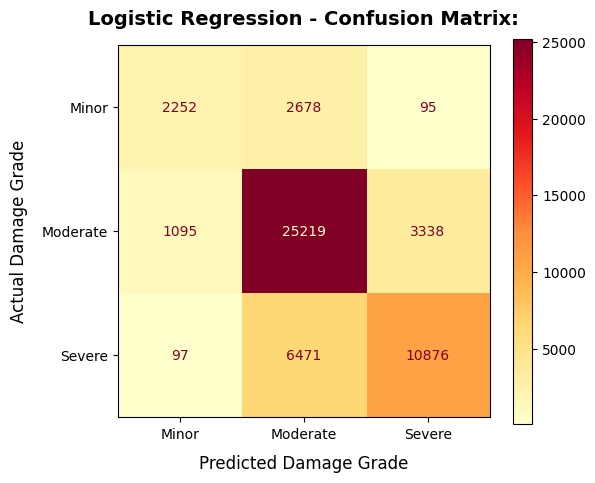

In [27]:
# Plot the confusion matrix to evaluate model performance and analyze prediction errors
lr_val_conf_matrix = confusion_matrix(y_val, lr_val_preds)
lr_val_conf_plot = ConfusionMatrixDisplay(confusion_matrix=lr_val_conf_matrix)

plt.figure(figsize=(6, 5))
lr_val_conf_plot.plot(cmap=plt.cm.YlOrRd, ax=plt.gca())
plt.title("Logistic Regression - Confusion Matrix:", fontsize=14, fontweight="bold", pad=15)
plt.xlabel('Predicted Damage Grade', fontsize=12, labelpad=10)
plt.ylabel('Actual Damage Grade', fontsize=12, labelpad=10)
plt.xticks(ticks=[0, 1, 2], labels=['Minor', 'Moderate', 'Severe'])
plt.yticks(ticks=[0, 1, 2], labels=['Minor', 'Moderate', 'Severe'])
plt.show()

In [28]:
# Compare training and validation macro F1 scores to audit the generalization gap for overfitting or underfitting
lr_train_preds = lr_pipeline.predict(X_train)
lr_train_macro_f1 = f1_score(y_train, lr_train_preds, average='macro')

display(Markdown("### Logistic Regression - Overfitting Check:"))
display(Markdown(f"**Training Macro F1:** {lr_train_macro_f1:.4f}"))
display(Markdown(f"**Validation Macro F1:** {lr_val_macro_f1:.4f}"))

### Logistic Regression - Overfitting Check:

**Training Macro F1:** 0.6828

**Validation Macro F1:** 0.6682

In [29]:
# Bundle preprocessing and model training to handle mixed features and prevent data leakage
rf_preprocessor = ColumnTransformer(
    transformers=[
        ('binary', 'passthrough', binary_cols),
        ('low_card_cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_low_cols),
        ('high_card_cat', TargetEncoder(), categorical_high_cols),
        ('numeric', StandardScaler(), numerical_cols)
    ]
)

rf_pipeline = Pipeline(steps=[
    ('preprocessor', rf_preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

rf_pipeline.set_output(transform="pandas")
rf_pipeline.fit(X_train, y_train);

In [30]:
# Transform datasets and inspect shapes and samples to verify preprocessing outputs
X_train_rf_transformed = rf_pipeline.named_steps['preprocessor'].transform(X_train)
X_val_rf_transformed = rf_pipeline.named_steps['preprocessor'].transform(X_val)

display(Markdown(f"**Random Forest - X_train Transformed Shape:** {X_train_rf_transformed.shape}"))
display(Markdown(f"**Random Forest - X_val Transformed Shape:** {X_val_rf_transformed.shape}"))
display(Markdown("### Random Forest - X_train Sample:"), X_train_rf_transformed.head(3))
display(Markdown("### Random Forest - X_val Sample:"), X_val_rf_transformed.head(3))

**Random Forest - X_train Transformed Shape:** (208480, 74)

**Random Forest - X_val Transformed Shape:** (52121, 74)

### Random Forest - X_train Sample:

,binary__has_superstructure_adobe_mud,binary__has_superstructure_mud_mortar_stone,binary__has_superstructure_stone_flag,binary__has_superstructure_cement_mortar_stone,binary__has_superstructure_mud_mortar_brick,binary__has_superstructure_cement_mortar_brick,binary__has_superstructure_timber,binary__has_superstructure_bamboo,binary__has_superstructure_rc_non_engineered,binary__has_superstructure_rc_engineered,binary__has_superstructure_other,binary__has_secondary_use,binary__has_secondary_use_agriculture,binary__has_secondary_use_hotel,binary__has_secondary_use_rental,binary__has_secondary_use_institution,binary__has_secondary_use_school,binary__has_secondary_use_industry,binary__has_secondary_use_health_post,binary__has_secondary_use_gov_office,binary__has_secondary_use_use_police,binary__has_secondary_use_other,low_card_cat__land_surface_condition_n,low_card_cat__land_surface_condition_o,low_card_cat__land_surface_condition_t,low_card_cat__foundation_type_h,low_card_cat__foundation_type_i,low_card_cat__foundation_type_r,low_card_cat__foundation_type_u,low_card_cat__foundation_type_w,low_card_cat__roof_type_n,low_card_cat__roof_type_q,low_card_cat__roof_type_x,low_card_cat__ground_floor_type_f,low_card_cat__ground_floor_type_m,low_card_cat__ground_floor_type_v,low_card_cat__ground_floor_type_x,low_card_cat__ground_floor_type_z,low_card_cat__other_floor_type_j,low_card_cat__other_floor_type_q,low_card_cat__other_floor_type_s,low_card_cat__other_floor_type_x,low_card_cat__position_j,low_card_cat__position_o,low_card_cat__position_s,low_card_cat__position_t,low_card_cat__plan_configuration_a,low_card_cat__plan_configuration_c,low_card_cat__plan_configuration_d,low_card_cat__plan_configuration_f,low_card_cat__plan_configuration_m,low_card_cat__plan_configuration_n,low_card_cat__plan_configuration_o,low_card_cat__plan_configuration_q,low_card_cat__plan_configuration_s,low_card_cat__plan_configuration_u,low_card_cat__legal_ownership_status_a,low_card_cat__legal_ownership_status_r,low_card_cat__legal_ownership_status_v,low_card_cat__legal_ownership_status_w,high_card_cat__geo_level_1_id_1,high_card_cat__geo_level_1_id_2,high_card_cat__geo_level_1_id_3,high_card_cat__geo_level_2_id_1,high_card_cat__geo_level_2_id_2,high_card_cat__geo_level_2_id_3,high_card_cat__geo_level_3_id_1,high_card_cat__geo_level_3_id_2,high_card_cat__geo_level_3_id_3,numeric__count_floors_pre_eq,numeric__age,numeric__area_percentage,numeric__height_percentage,numeric__count_families
185461,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.022092,0.394542,0.583359,0.022937,0.588173,0.388700,0.0,0.413089,0.582635,1.197536,-0.088956,-0.458306,0.297285,0.039014
190537,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.031723,0.604502,0.363768,0.036554,0.623360,0.340044,0.0,0.535075,0.463044,-0.178044,-0.088956,-0.458306,-0.226390,0.039014
232781,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.022092,0.394542,0.583359,0.000000,0.626484,0.373198,0.0,0.878499,0.120583,1.197536,0.251137,-0.458306,-0.226390,7.211517


### Random Forest - X_val Sample:

,binary__has_superstructure_adobe_mud,binary__has_superstructure_mud_mortar_stone,binary__has_superstructure_stone_flag,binary__has_superstructure_cement_mortar_stone,binary__has_superstructure_mud_mortar_brick,binary__has_superstructure_cement_mortar_brick,binary__has_superstructure_timber,binary__has_superstructure_bamboo,binary__has_superstructure_rc_non_engineered,binary__has_superstructure_rc_engineered,binary__has_superstructure_other,binary__has_secondary_use,binary__has_secondary_use_agriculture,binary__has_secondary_use_hotel,binary__has_secondary_use_rental,binary__has_secondary_use_institution,binary__has_secondary_use_school,binary__has_secondary_use_industry,binary__has_secondary_use_health_post,binary__has_secondary_use_gov_office,binary__has_secondary_use_use_police,binary__has_secondary_use_other,low_card_cat__land_surface_condition_n,low_card_cat__land_surface_condition_o,low_card_cat__land_surface_condition_t,low_card_cat__foundation_type_h,low_card_cat__foundation_type_i,low_card_cat__foundation_type_r,low_card_cat__foundation_type_u,low_card_cat__foundation_type_w,low_card_cat__roof_type_n,low_card_cat__roof_type_q,low_card_cat__roof_type_x,low_card_cat__ground_floor_type_f,low_card_cat__ground_floor_type_m,low_card_cat__ground_floor_type_v,low_card_cat__ground_floor_type_x,low_card_cat__ground_floor_type_z,low_card_cat__other_floor_type_j,low_card_cat__other_floor_type_q,low_card_cat__other_floor_type_s,low_card_cat__other_floor_type_x,low_card_cat__position_j,low_card_cat__position_o,low_card_cat__position_s,low_card_cat__position_t,low_card_cat__plan_configuration_a,low_card_cat__plan_configuration_c,low_card_cat__plan_configuration_d,low_card_cat__plan_configuration_f,low_card_cat__plan_configuration_m,low_card_cat__plan_configuration_n,low_card_cat__plan_configuration_o,low_card_cat__plan_configuration_q,low_card_cat__plan_configuration_s,low_card_cat__plan_configuration_u,low_card_cat__legal_ownership_status_a,low_card_cat__legal_ownership_status_r,low_card_cat__legal_ownership_status_v,low_card_cat__legal_ownership_status_w,high_card_cat__geo_level_1_id_1,high_card_cat__geo_level_1_id_2,high_card_cat__geo_level_1_id_3,high_card_cat__geo_level_2_id_1,high_card_cat__geo_level_2_id_2,high_card_cat__geo_level_2_id_3,high_card_cat__geo_level_3_id_1,high_card_cat__geo_level_3_id_2,high_card_cat__geo_level_3_id_3,numeric__count_floors_pre_eq,numeric__age,numeric__area_percentage,numeric__height_percentage,numeric__count_families
124536,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.086741,0.662871,0.250388,0.141920,0.619173,0.238816,0.190046,0.492593,0.316106,1.197536,0.455193,0.905476,1.344633,0.039014
112152,0,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.192820,0.687315,0.119853,0.059823,0.741714,0.198419,0.027588,0.699692,0.271776,-1.553624,-0.088956,-0.685603,-0.750064,0.039014
93613,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.192820,0.687315,0.119853,0.381430,0.544007,0.070628,0.509801,0.369343,0.093620,-1.553624,-0.361031,-0.458306,-1.273738,-2.351821


In [31]:
# Generate validation predictions and compute micro and macro F1 scores to evaluate overall classification performance.
rf_val_preds = rf_pipeline.predict(X_val)
rf_val_micro_f1 = f1_score(y_val, rf_val_preds, average='micro')
rf_val_macro_f1 = f1_score(y_val, rf_val_preds, average='macro')

display(Markdown(f"**Random Forest - Micro F1 Score:** {rf_val_micro_f1:.4f}"))
display(Markdown(f"**Random Forest - Macro F1 Score:** {rf_val_macro_f1:.4f}"))

**Random Forest - Micro F1 Score:** 0.7489

**Random Forest - Macro F1 Score:** 0.6970

In [32]:
# Generate and display a styled classification report table with gradient highlighting for comprehensive per-class evaluation.
rf_val_class_report = classification_report(y_val, rf_val_preds, output_dict=True, zero_division=0)
rf_val_class_df = pd.DataFrame(rf_val_class_report).transpose()

display(Markdown("### Random Forest - Classification Report:"))
display(rf_val_class_df.style.format("{:.4f}").background_gradient(cmap="YlOrRd", subset=['precision', 'recall', 'f1-score', 'support']))

### Random Forest - Classification Report:

,precision,recall,f1-score,support
1,0.6832,0.5300,0.5969,5025.0000
2,0.7495,0.8487,0.7960,29652.0000
3,0.7650,0.6422,0.6982,17444.0000
accuracy,0.7489,0.7489,0.7489,0.7489
macro avg,0.7325,0.6736,0.6970,52121.0000
weighted avg,0.7483,0.7489,0.7441,52121.0000


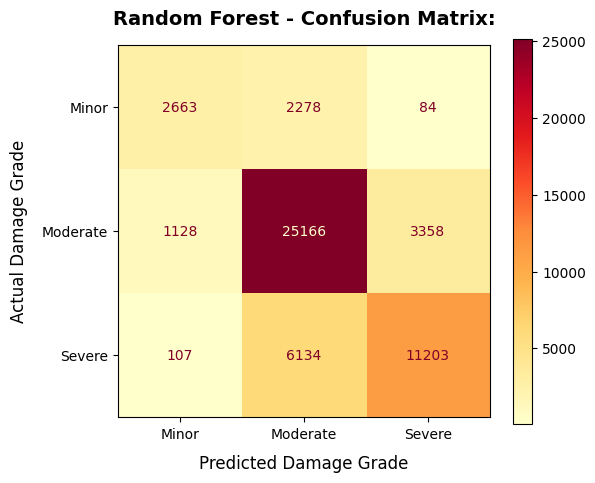

In [33]:
# Plot the confusion matrix to evaluate model performance and analyze prediction errors
rf_val_conf_matrix = confusion_matrix(y_val, rf_val_preds)
rf_val_conf_plot = ConfusionMatrixDisplay(confusion_matrix=rf_val_conf_matrix)

plt.figure(figsize=(6, 5))
rf_val_conf_plot.plot(cmap=plt.cm.YlOrRd, ax=plt.gca())
plt.title("Random Forest - Confusion Matrix:", fontsize=14, fontweight="bold", pad=15)
plt.xlabel('Predicted Damage Grade', fontsize=12, labelpad=10)
plt.ylabel('Actual Damage Grade', fontsize=12, labelpad=10)
plt.xticks(ticks=[0, 1, 2], labels=['Minor', 'Moderate', 'Severe'])
plt.yticks(ticks=[0, 1, 2], labels=['Minor', 'Moderate', 'Severe'])
plt.show()

In [34]:
# Compare training and validation macro F1 scores to audit the generalization gap for overfitting or underfitting
rf_train_preds = rf_pipeline.predict(X_train)
rf_train_macro_f1 = f1_score(y_train, rf_train_preds, average='macro')

display(Markdown("### Random Forest - Overfitting Check:"))
display(Markdown(f"**Training Macro F1:** {rf_train_macro_f1:.4f}"))
display(Markdown(f"**Validation Macro F1:** {rf_val_macro_f1:.4f}"))

### Random Forest - Overfitting Check:

**Training Macro F1:** 0.8235

**Validation Macro F1:** 0.6970

In [35]:
# Bundle preprocessing and CatBoost into a leak-free pipeline with pandas-compatible feature names.
raw_categorical_cols = categorical_low_cols + categorical_high_cols
cb_categorical_cols = [f"categorical__{col}" for col in raw_categorical_cols]

cb_preprocessor = ColumnTransformer(
    transformers=[
        ('binary', 'passthrough', binary_cols),
        ('categorical', 'passthrough', raw_categorical_cols),
        ('numeric', StandardScaler(), numerical_cols)
    ]
)

cb_pipeline = Pipeline(steps=[
    ('preprocessor', cb_preprocessor),
    ('model', CatBoostClassifier(cat_features=cb_categorical_cols, auto_class_weights='SqrtBalanced', task_type='GPU', random_state=42, verbose=0))
])

cb_pipeline.set_output(transform="pandas")
cb_pipeline.fit(X_train, y_train);

In [36]:
# Transform datasets and inspect shapes and samples to verify preprocessing outputs
X_train_cb_transformed = cb_pipeline.named_steps['preprocessor'].transform(X_train)
X_val_cb_transformed = cb_pipeline.named_steps['preprocessor'].transform(X_val)

display(Markdown(f"**CatBoost - X_train Transformed Shape:** {X_train_cb_transformed.shape}"))
display(Markdown(f"**CatBoost - X_val Transformed Shape:** {X_val_cb_transformed.shape}"))
display(Markdown("### CatBoost - X_train Sample:"), X_train_cb_transformed.head(3))
display(Markdown("### CatBoost - X_val Sample:"), X_val_cb_transformed.head(3))

**CatBoost - X_train Transformed Shape:** (208480, 38)

**CatBoost - X_val Transformed Shape:** (52121, 38)

### CatBoost - X_train Sample:

,binary__has_superstructure_adobe_mud,binary__has_superstructure_mud_mortar_stone,binary__has_superstructure_stone_flag,binary__has_superstructure_cement_mortar_stone,binary__has_superstructure_mud_mortar_brick,binary__has_superstructure_cement_mortar_brick,binary__has_superstructure_timber,binary__has_superstructure_bamboo,binary__has_superstructure_rc_non_engineered,binary__has_superstructure_rc_engineered,binary__has_superstructure_other,binary__has_secondary_use,binary__has_secondary_use_agriculture,binary__has_secondary_use_hotel,binary__has_secondary_use_rental,binary__has_secondary_use_institution,binary__has_secondary_use_school,binary__has_secondary_use_industry,binary__has_secondary_use_health_post,binary__has_secondary_use_gov_office,binary__has_secondary_use_use_police,binary__has_secondary_use_other,categorical__land_surface_condition,categorical__foundation_type,categorical__roof_type,categorical__ground_floor_type,categorical__other_floor_type,categorical__position,categorical__plan_configuration,categorical__legal_ownership_status,categorical__geo_level_1_id,categorical__geo_level_2_id,categorical__geo_level_3_id,numeric__count_floors_pre_eq,numeric__age,numeric__area_percentage,numeric__height_percentage,numeric__count_families
185461,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,t,r,n,f,q,s,d,v,21,935,5965,1.197536,-0.088956,-0.458306,0.297285,0.039014
190537,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,t,r,n,f,q,t,d,v,3,1229,1099,-0.178044,-0.088956,-0.458306,-0.226390,0.039014
232781,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,t,r,q,f,q,s,d,w,21,1219,2705,1.197536,0.251137,-0.458306,-0.226390,7.211517


### CatBoost - X_val Sample:

,binary__has_superstructure_adobe_mud,binary__has_superstructure_mud_mortar_stone,binary__has_superstructure_stone_flag,binary__has_superstructure_cement_mortar_stone,binary__has_superstructure_mud_mortar_brick,binary__has_superstructure_cement_mortar_brick,binary__has_superstructure_timber,binary__has_superstructure_bamboo,binary__has_superstructure_rc_non_engineered,binary__has_superstructure_rc_engineered,binary__has_superstructure_other,binary__has_secondary_use,binary__has_secondary_use_agriculture,binary__has_secondary_use_hotel,binary__has_secondary_use_rental,binary__has_secondary_use_institution,binary__has_secondary_use_school,binary__has_secondary_use_industry,binary__has_secondary_use_health_post,binary__has_secondary_use_gov_office,binary__has_secondary_use_use_police,binary__has_secondary_use_other,categorical__land_surface_condition,categorical__foundation_type,categorical__roof_type,categorical__ground_floor_type,categorical__other_floor_type,categorical__position,categorical__plan_configuration,categorical__legal_ownership_status,categorical__geo_level_1_id,categorical__geo_level_2_id,categorical__geo_level_3_id,numeric__count_floors_pre_eq,numeric__age,numeric__area_percentage,numeric__height_percentage,numeric__count_families
124536,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,n,r,q,f,q,t,d,w,6,1350,3790,1.197536,0.455193,0.905476,1.344633,0.039014
112152,0,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,n,w,n,f,j,s,d,a,20,863,11793,-1.553624,-0.088956,-0.685603,-0.750064,0.039014
93613,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,t,r,n,f,j,s,d,v,20,214,10569,-1.553624,-0.361031,-0.458306,-1.273738,-2.351821


In [37]:
# Generate validation predictions and compute micro and macro F1 scores to evaluate overall classification performance.
cb_val_preds = cb_pipeline.predict(X_val)
cb_val_micro_f1 = f1_score(y_val, cb_val_preds, average='micro')
cb_val_macro_f1 = f1_score(y_val, cb_val_preds, average='macro')

display(Markdown(f"**CatBoost - Micro F1 Score:** {cb_val_micro_f1:.4f}"))
display(Markdown(f"**CatBoost - Macro F1 Score:** {cb_val_macro_f1:.4f}"))

**CatBoost - Micro F1 Score:** 0.7338

**CatBoost - Macro F1 Score:** 0.6970

In [38]:
# Generate and display a styled classification report table with gradient highlighting for comprehensive per-class evaluation.
cb_val_class_report = classification_report(y_val, cb_val_preds, output_dict=True, zero_division=0)
cb_val_class_df = pd.DataFrame(cb_val_class_report).transpose()

display(Markdown("### CatBoost - Classification Report:"))
display(cb_val_class_df.style.format("{:.4f}").background_gradient(cmap="YlOrRd", subset=['precision', 'recall', 'f1-score', 'support']))

### CatBoost - Classification Report:

,precision,recall,f1-score,support
1,0.5544,0.6762,0.6093,5025.0000
2,0.7735,0.7664,0.7700,29652.0000
3,0.7297,0.6949,0.7119,17444.0000
accuracy,0.7338,0.7338,0.7338,0.7338
macro avg,0.6859,0.7125,0.6970,52121.0000
weighted avg,0.7377,0.7338,0.7350,52121.0000


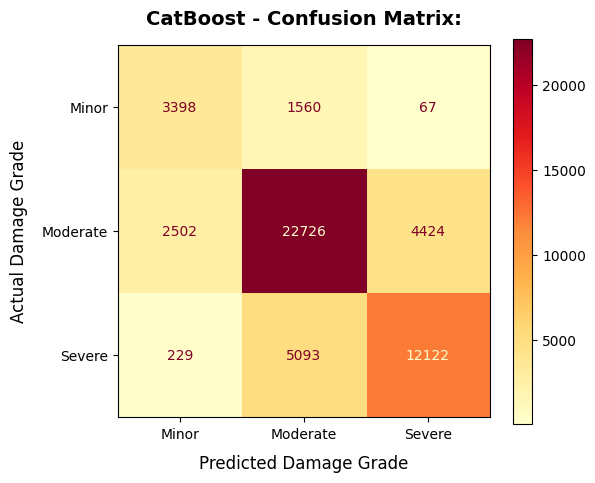

In [39]:
# Plot the confusion matrix to evaluate model performance and analyze prediction errors
cb_val_conf_matrix = confusion_matrix(y_val, cb_val_preds)
cb_val_conf_plot = ConfusionMatrixDisplay(confusion_matrix=cb_val_conf_matrix)

plt.figure(figsize=(6, 5))
cb_val_conf_plot.plot(cmap=plt.cm.YlOrRd, ax=plt.gca())
plt.title("CatBoost - Confusion Matrix:", fontsize=14, fontweight="bold", pad=15)
plt.xlabel('Predicted Damage Grade', fontsize=12, labelpad=10)
plt.ylabel('Actual Damage Grade', fontsize=12, labelpad=10)
plt.xticks(ticks=[0, 1, 2], labels=['Minor', 'Moderate', 'Severe'])
plt.yticks(ticks=[0, 1, 2], labels=['Minor', 'Moderate', 'Severe'])
plt.show()

In [40]:
# Compare training and validation macro F1 scores to audit the generalization gap for overfitting or underfitting
cb_train_preds = cb_pipeline.predict(X_train)
cb_train_macro_f1 = f1_score(y_train, cb_train_preds, average='macro')

display(Markdown("### CatBoost - Overfitting Check:"))
display(Markdown(f"**Training Macro F1:** {cb_train_macro_f1:.4f}"))
display(Markdown(f"**Validation Macro F1:** {cb_val_macro_f1:.4f}"))

### CatBoost - Overfitting Check:

**Training Macro F1:** 0.7227

**Validation Macro F1:** 0.6970

In [41]:
# Benchmark base models using performance and generalization metrics to identify the best architecture and detect overfitting.
evaluation_metrics_dict = {
    "Model": ["Logistic Regression", "Random Forest", "CatBoost"],
    "Training Macro F1": [lr_train_macro_f1, rf_train_macro_f1, cb_train_macro_f1],
    "Validation Macro F1": [lr_val_macro_f1, rf_val_macro_f1, cb_val_macro_f1],
    "Validation Micro F1": [lr_val_micro_f1, rf_val_micro_f1, cb_val_micro_f1],
    "Generalization Gap": [
        lr_train_macro_f1 - lr_val_macro_f1,
        rf_train_macro_f1 - rf_val_macro_f1,
        cb_train_macro_f1 - cb_val_macro_f1
    ],
}

model_metrics_df = pd.DataFrame(evaluation_metrics_dict)
model_metrics_df.set_index("Model", inplace=True)


display(Markdown("### Cross-Model Evaluation & Generalization Audit:"), model_metrics_df.round(4))

### Cross-Model Evaluation & Generalization Audit:

,Training Macro F1,Validation Macro F1,Validation Micro F1,Generalization Gap
Model,,,,
Logistic Regression,0.6828,0.6682,0.7357,0.0145
Random Forest,0.8235,0.6970,0.7489,0.1264
CatBoost,0.7227,0.6970,0.7338,0.0256


## 6. Hyperparameter Optimization via Optuna
Based on baseline performance, **CatBoost** demonstrated superior capability with tabular data containing mixed categorical and numerical features. To maximize its predictive power without overfitting, we implement an automated hyperparameter optimization study using **Optuna** combined with **5-Fold Stratified Cross-Validation**, optimizing for Macro F1-score.

In [42]:
# Define a cross-validated Optuna objective function to tune CatBoost hyperparameters securely and prevent data leakage.
best_categorical_cols = [f"categorical__{col}" for col in raw_categorical_cols]

def objective(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 100, 1000),
        'depth': trial.suggest_int('depth', 4, 8),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.2, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-1, 10.0, log=True),
        'random_strength': trial.suggest_float('random_strength', 1e-3, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'random_state': 42,
        'verbose': 0
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    fold_scores = []

    for train_idx, val_idx in cv.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
        X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]

        trial_preprocessor = ColumnTransformer(
            transformers=[
                ('binary', 'passthrough', binary_cols),
                ('categorical', 'passthrough', raw_categorical_cols),
                ('numeric', StandardScaler(), numerical_cols)
            ]
        )

        trial_pipeline = Pipeline(steps=[
            ('preprocessor', trial_preprocessor),
            ('model', CatBoostClassifier(cat_features=best_categorical_cols, auto_class_weights='SqrtBalanced', task_type='GPU', **params))
        ])

        trial_pipeline.set_output(transform="pandas")
        trial_pipeline.fit(X_tr, y_tr)

        preds = trial_pipeline.predict(X_va)
        score = f1_score(y_va, preds, average='macro')
        fold_scores.append(score)

    return np.mean(fold_scores)

In [43]:
# Execute the Optuna optimization study to iteratively search for and retrieve the best-performing hyperparameters.
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=100, show_progress_bar=True)

display(Markdown(f"**Best Cross-Validation Macro F1:** {study.best_value:.4f}"))
display(Markdown("### Best Hyperparameters Found:"), study.best_params)

[I 2026-11-03 20:37:36,096] A new study created in memory with name: no-name-e6a478da-54ab-4f20-b12a-139fd0c258c0


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-11-03 20:38:33,602] Trial 0 finished with value: 0.6853871873396111 and parameters: {'iterations': 437, 'depth': 8, 'learning_rate': 0.0483437145318464, 'l2_leaf_reg': 1.5751320499779735, 'random_strength': 0.004207988669606638, 'bagging_temperature': 0.15599452033620265}. Best is trial 0 with value: 0.6853871873396111.
[I 2026-11-03 20:39:02,923] Trial 1 finished with value: 0.66376439215732 and parameters: {'iterations': 152, 'depth': 8, 'learning_rate': 0.02416482602989751, 'l2_leaf_reg': 2.607024758370768, 'random_strength': 0.0012087541473056963, 'bagging_temperature': 0.9699098521619943}. Best is trial 0 with value: 0.6853871873396111.
[I 2026-11-03 20:39:56,957] Trial 2 finished with value: 0.6488067766156874 and parameters: {'iterations': 850, 'depth': 5, 'learning_rate': 0.002620503255096255, 'l2_leaf_reg': 0.2327067708383781, 'random_strength': 0.016480446427978974, 'bagging_temperature': 0.5247564316322378}. Best is trial 0 with value: 0.6853871873396111.
[I 2026-11-

**Best Cross-Validation Macro F1:** 0.6941

### Best Hyperparameters Found:

{'iterations': 963,
 'depth': 8,
 'learning_rate': 0.09962315046696274,
 'l2_leaf_reg': 0.9312065814882233,
 'random_strength': 0.002263512236734248,
 'bagging_temperature': 0.4991966970520894}

<Axes: title={'center': 'Optimization History Plot'}, xlabel='Trial', ylabel='Objective Value'>

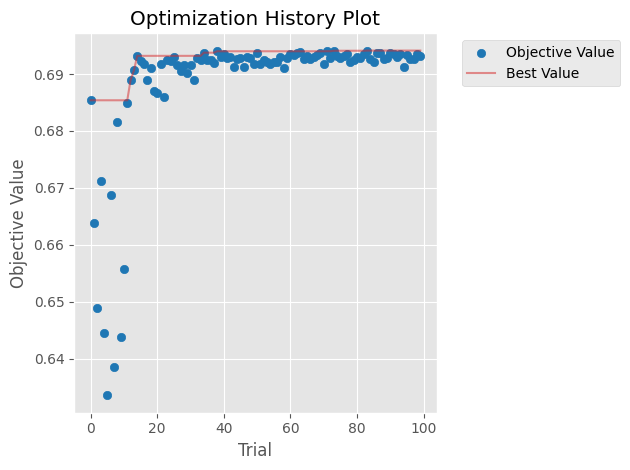

In [44]:
# Visualize optimization history across trials to track metric improvement, convergence, and search progress.
warnings.filterwarnings("ignore", message=".* is experimental.*")
optuna_plt.plot_optimization_history(study)

## 7. Final Model Training & Feature Importance Interpretation
Using the optimal hyperparameters discovered during the Optuna search, we train our final production-grade CatBoost pipeline. We evaluate its performance using classification reports, confusion matrices, and feature importance extraction to understand what structural factors drive earthquake damage.

In [45]:
# Build and train the final pipeline using Optuna's best hyperparameters to maximize predictive performance and prevent data leakage.
best_preprocessor = ColumnTransformer(
            transformers=[
                ('binary', 'passthrough', binary_cols),
                ('categorical', 'passthrough', raw_categorical_cols),
                ('numeric', StandardScaler(), numerical_cols)
            ]
        )

best_pipeline = Pipeline(steps=[
    ('preprocessor', best_preprocessor),
    ('model', CatBoostClassifier(cat_features=best_categorical_cols, auto_class_weights='SqrtBalanced', task_type='GPU', **study.best_params, random_state=42, verbose=0))
])

best_pipeline.set_output(transform="pandas")
best_pipeline.fit(X_train, y_train);

In [46]:
# Verify preprocessed feature shapes and inspect sample data to ensure the pipeline transformed the training and validation sets correctly.
X_train_best_transformed = best_pipeline.named_steps['preprocessor'].transform(X_train)
X_val_best_transformed = best_pipeline.named_steps['preprocessor'].transform(X_val)

display(Markdown(f"**Best Model - X_train Transformed Shape:** {X_train_best_transformed.shape}"))
display(Markdown(f"**Best Model - X_val Transformed Shape:** {X_val_best_transformed.shape}"))
display(Markdown("### Best Model - X_train Sample:"), X_train_best_transformed.head(3))
display(Markdown("### Best Model - X_val Sample:"), X_val_best_transformed.head(3))

**Best Model - X_train Transformed Shape:** (208480, 38)

**Best Model - X_val Transformed Shape:** (52121, 38)

### Best Model - X_train Sample:

,binary__has_superstructure_adobe_mud,binary__has_superstructure_mud_mortar_stone,binary__has_superstructure_stone_flag,binary__has_superstructure_cement_mortar_stone,binary__has_superstructure_mud_mortar_brick,binary__has_superstructure_cement_mortar_brick,binary__has_superstructure_timber,binary__has_superstructure_bamboo,binary__has_superstructure_rc_non_engineered,binary__has_superstructure_rc_engineered,binary__has_superstructure_other,binary__has_secondary_use,binary__has_secondary_use_agriculture,binary__has_secondary_use_hotel,binary__has_secondary_use_rental,binary__has_secondary_use_institution,binary__has_secondary_use_school,binary__has_secondary_use_industry,binary__has_secondary_use_health_post,binary__has_secondary_use_gov_office,binary__has_secondary_use_use_police,binary__has_secondary_use_other,categorical__land_surface_condition,categorical__foundation_type,categorical__roof_type,categorical__ground_floor_type,categorical__other_floor_type,categorical__position,categorical__plan_configuration,categorical__legal_ownership_status,categorical__geo_level_1_id,categorical__geo_level_2_id,categorical__geo_level_3_id,numeric__count_floors_pre_eq,numeric__age,numeric__area_percentage,numeric__height_percentage,numeric__count_families
185461,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,t,r,n,f,q,s,d,v,21,935,5965,1.197536,-0.088956,-0.458306,0.297285,0.039014
190537,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,t,r,n,f,q,t,d,v,3,1229,1099,-0.178044,-0.088956,-0.458306,-0.226390,0.039014
232781,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,t,r,q,f,q,s,d,w,21,1219,2705,1.197536,0.251137,-0.458306,-0.226390,7.211517


### Best Model - X_val Sample:

,binary__has_superstructure_adobe_mud,binary__has_superstructure_mud_mortar_stone,binary__has_superstructure_stone_flag,binary__has_superstructure_cement_mortar_stone,binary__has_superstructure_mud_mortar_brick,binary__has_superstructure_cement_mortar_brick,binary__has_superstructure_timber,binary__has_superstructure_bamboo,binary__has_superstructure_rc_non_engineered,binary__has_superstructure_rc_engineered,binary__has_superstructure_other,binary__has_secondary_use,binary__has_secondary_use_agriculture,binary__has_secondary_use_hotel,binary__has_secondary_use_rental,binary__has_secondary_use_institution,binary__has_secondary_use_school,binary__has_secondary_use_industry,binary__has_secondary_use_health_post,binary__has_secondary_use_gov_office,binary__has_secondary_use_use_police,binary__has_secondary_use_other,categorical__land_surface_condition,categorical__foundation_type,categorical__roof_type,categorical__ground_floor_type,categorical__other_floor_type,categorical__position,categorical__plan_configuration,categorical__legal_ownership_status,categorical__geo_level_1_id,categorical__geo_level_2_id,categorical__geo_level_3_id,numeric__count_floors_pre_eq,numeric__age,numeric__area_percentage,numeric__height_percentage,numeric__count_families
124536,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,n,r,q,f,q,t,d,w,6,1350,3790,1.197536,0.455193,0.905476,1.344633,0.039014
112152,0,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,n,w,n,f,j,s,d,a,20,863,11793,-1.553624,-0.088956,-0.685603,-0.750064,0.039014
93613,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,t,r,n,f,j,s,d,v,20,214,10569,-1.553624,-0.361031,-0.458306,-1.273738,-2.351821


In [47]:
# Generate validation predictions and compute micro and macro F1 scores to evaluate overall classification performance.
best_val_preds = best_pipeline.predict(X_val)
best_val_micro_f1 = f1_score(y_val, best_val_preds, average='micro')
best_val_macro_f1 = f1_score(y_val, best_val_preds, average='macro')

display(Markdown(f"**Best Model - Micro F1 Score:** {best_val_micro_f1:.4f}"))
display(Markdown(f"**Best Model - Macro F1 Score:** {best_val_macro_f1:.4f}"))

**Best Model - Micro F1 Score:** 0.7362

**Best Model - Macro F1 Score:** 0.7002

In [48]:
# Generate and display a styled classification report table with gradient highlighting for comprehensive per-class evaluation.
best_val_class_report = classification_report(y_val, best_val_preds, output_dict=True, zero_division=0)
best_val_class_df = pd.DataFrame(best_val_class_report).transpose()

display(Markdown("### Best Model - Classification Report:"))
display(best_val_class_df.style.format("{:.4f}").background_gradient(cmap="YlOrRd", subset=['precision', 'recall', 'f1-score', 'support']))

### Best Model - Classification Report:

,precision,recall,f1-score,support
1,0.5639,0.6772,0.6154,5025.0000
2,0.7740,0.7702,0.7721,29652.0000
3,0.7317,0.6954,0.7131,17444.0000
accuracy,0.7362,0.7362,0.7362,0.7362
macro avg,0.6899,0.7143,0.7002,52121.0000
weighted avg,0.7396,0.7362,0.7373,52121.0000


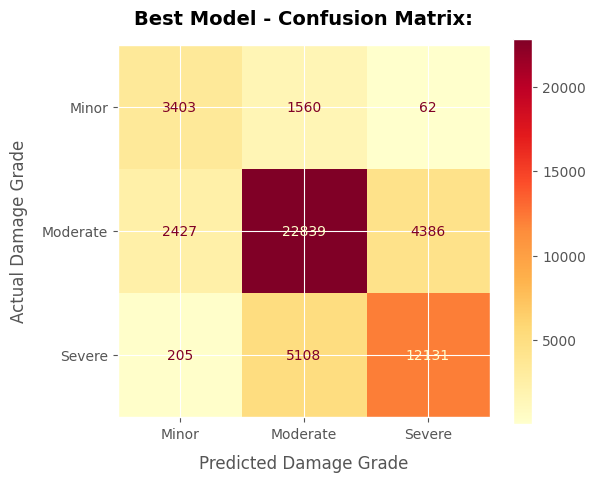

In [49]:
# Plot the confusion matrix to evaluate model performance and analyze prediction errors
best_val_conf_matrix = confusion_matrix(y_val, best_val_preds)
best_val_conf_plot = ConfusionMatrixDisplay(confusion_matrix=best_val_conf_matrix)

plt.figure(figsize=(6, 5))
best_val_conf_plot.plot(cmap=plt.cm.YlOrRd, ax=plt.gca())
plt.title("Best Model - Confusion Matrix:", fontsize=14, fontweight="bold", pad=15)
plt.xlabel('Predicted Damage Grade', fontsize=12, labelpad=10)
plt.ylabel('Actual Damage Grade', fontsize=12, labelpad=10)
plt.xticks(ticks=[0, 1, 2], labels=['Minor', 'Moderate', 'Severe'])
plt.yticks(ticks=[0, 1, 2], labels=['Minor', 'Moderate', 'Severe'])
plt.show()

In [50]:
# Compare training and validation macro F1 scores to evaluate the generalization gap and check for overfitting.
best_train_preds = best_pipeline.predict(X_train)
best_train_macro_f1 = f1_score(y_train, best_train_preds, average='macro')

display(Markdown("### Best Model - Overfitting Check:"))
display(Markdown(f"**Training Macro F1:** {best_train_macro_f1:.4f}"))
display(Markdown(f"**Validation Macro F1:** {best_val_macro_f1:.4f}"))

### Best Model - Overfitting Check:

**Training Macro F1:** 0.7395

**Validation Macro F1:** 0.7002

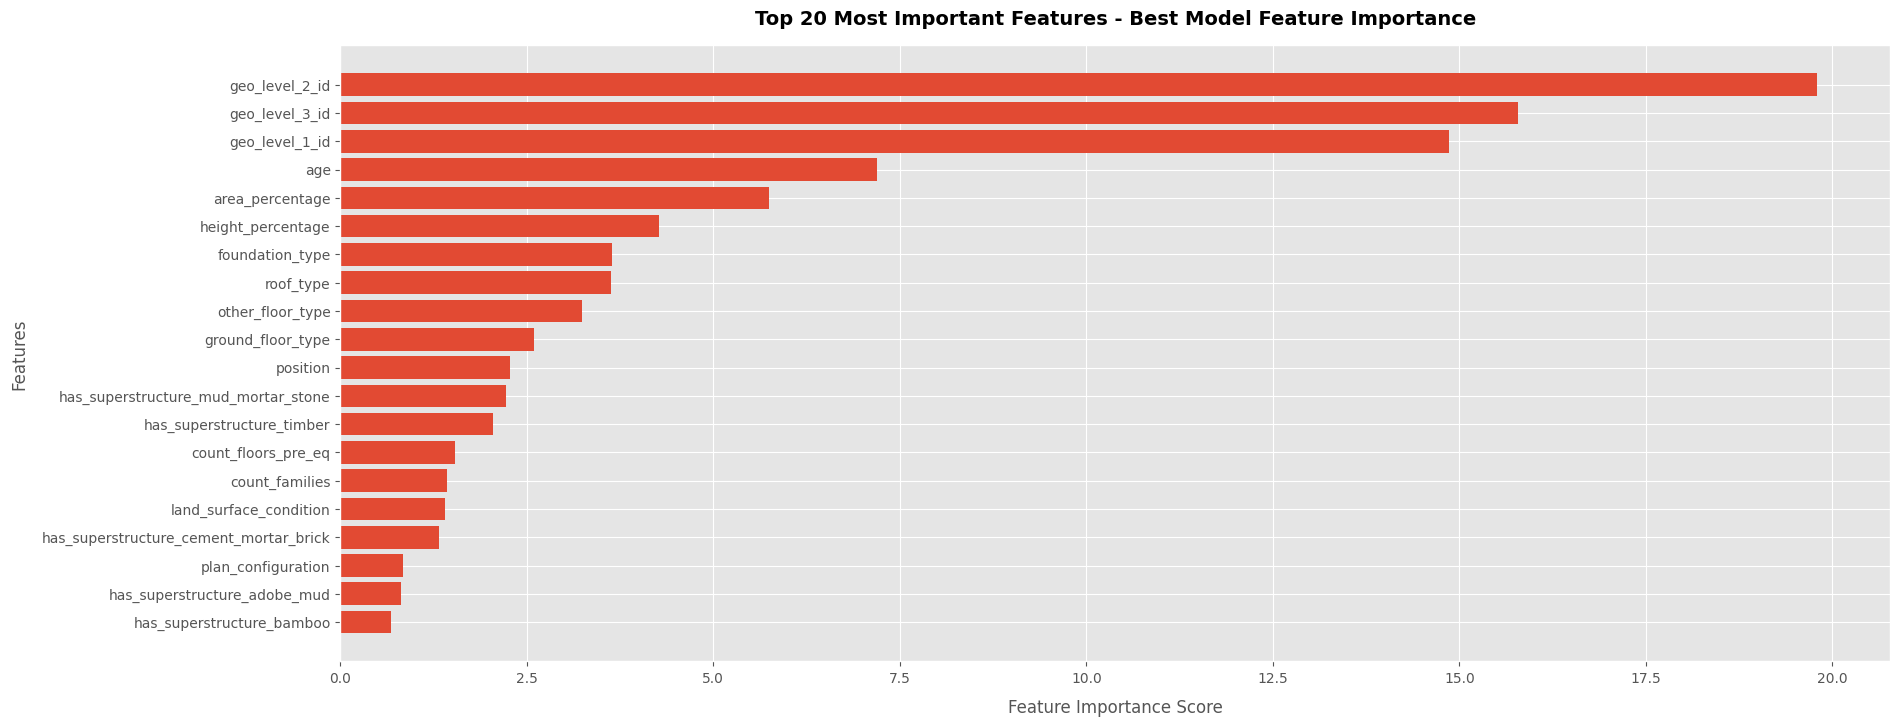

In [51]:
# Plot feature importances to identify which variables mostly influence the model's predictions
feature_importances = best_pipeline.named_steps['model'].get_feature_importance()
raw_feature_names = best_pipeline.named_steps['preprocessor'].get_feature_names_out()
feature_names = [name.split('__')[-1] if '__' in name else name for name in raw_feature_names]
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=True)
importance_df_top = importance_df.tail(20)

plt.figure(figsize=(20, 8))
plt.barh(importance_df_top['Feature'], importance_df_top['Importance'])
plt.title("Top 20 Most Important Features - Best Model Feature Importance", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Feature Importance Score", fontsize=12, labelpad=10)
plt.ylabel("Features", fontsize=12, labelpad=10)
plt.show()

## 8. Actionable Insights for Seismologists and Urban Planners (Task 3)

<div style="border: 1px solid #e0e0e0; border-left: 4px solid #4A90E2; padding: 20px; border-radius: 6px;">
    
### Seismologist & Urban Planner Policy Suggestions
Based on feature importance analysis from the final tuned model, the primary structural and environmental drivers of building damage during the earthquake were categorized into four core domains. Below are data-driven recommendations for seismic risk mitigation:

#### 1. Geographical Vulnerability (`geo_level_1_id`, `geo_level_2_id`, `geo_level_3_id`)
- **Insights:** Geographic identifiers are dominant predictors of damage severity, indicating that specific sub-regions experience amplified seismic hazards, vulnerable soil conditions, or high local intensity profiles.
- **Recommendations:** Establish high-resolution **seismic microzonation maps**. Enforce strict land-use regulations that restrict high-density construction in high-risk seismic zones, and prioritize vulnerable regions for targeted infrastructure reinforcement.

#### 2. Structural History & Age (`age`)
- **Insights:** Building age serves as a strong indicator of structural degradation, long-term material fatigue, and non-compliance with modern seismic safety standards.
- **Recommendations:** Institute mandatory **structural health audits and safety certifications** for aging buildings. Implement government-backed **seismic retrofitting subsidies** for older properties, and safely decommission or rebuild severely degraded structures.

#### 3. Building Geometry & Dimensions (`area_percentage`, `height_percentage`)
- **Insights:** Building footprint area influences seismic energy absorption distribution, while height dictates dynamic amplification and structural wobble during ground motion.
- **Recommendations:** Enforce strict **aspect-ratio and height-to-width building codes** to control structural oscillation. Mandate symmetrical architectural footprints and ensure engineering designs comply with earthquake-resistant mass-distribution ratios.

#### 4. Architectural & Material Quality (`foundation_type`, `ground_floor_type`, `other_floor_type`, `roof_type`)
- **Insights:** Foundation resilience, floor diaphragm rigidity, and roof mass heavily dictate whether a building can withstand or dissipate seismic forces.
- **Recommendations:** Mandate resilient, engineered **foundation systems** (such as reinforced concrete tie beams or mat foundations). Require **lightweight, durable roofing materials** to minimize top-heavy inertia, and utilize ductile, high-quality materials across ground and upper-floor diaphragms.

</div>

## 9. Model Persistence & Inference Verification
To ensure the model can be deployed into production or used for future scoring, we serialize and save the fully trained pipeline using `joblib`. We then reload the model from disk and verify inference outputs on validation samples.

In [52]:
# Save the trained model pipeline to disk for future inference and deployment
model_filename = 'best_pipeline.pkl'
joblib.dump(best_pipeline, model_filename)

display(Markdown(f"**Model successfully saved to:** {model_filename}"))

**Model successfully saved to:** best_pipeline.pkl

In [53]:
# Load the saved model pipeline from disk and generate predictions on validation data
loaded_pipeline = joblib.load('best_pipeline.pkl')
predictions = loaded_pipeline.predict(X_val)

display(Markdown("### Loaded model predictions:"), predictions)

### Loaded model predictions:

array([[3],
       [2],
       [1],
       ...,
       [2],
       [2],
       [1]], shape=(52121, 1))

## 10. Project Challenge & Technical Mitigation Report

<div style="border: 1px solid #e0e0e0; border-left: 4px solid #4A90E2; padding: 20px; border-radius: 6px;">
    
### Project Challenge & Mitigation Report
During the development of the Earthquake Damage Prediction model, several technical and architectural challenges were encountered and successfully resolved:

#### 1. High Cardinality & Geographic Feature Encoding
* **Challenge:** The dataset contains high-cardinality geographic identifiers (`geo_level_1_id`, `geo_level_2_id`, `geo_level_3_id`) which scale up to thousands of unique sub-regions, making standard One-Hot Encoding impractical due to extreme dimensionality and sparsity.

* **Mitigation**: Implemented Target Encoding within scikit-learn pipelines to map high-cardinality categorical variables into meaningful numerical representations while strictly utilizing stratified cross-validation to prevent data leakage.

#### 2. Class Imbalance & Distributional Skew
* **Challenge**: The target variable (`damage_grade`) exhibits class imbalance across its three severity levels, which risks biasing predictions toward majority classes.

* **Mitigation**: Applied Stratified Train-Test Splits and Stratified K-Fold Cross-Validation to ensure class proportions remain consistent across training, validation, and optimization folds.

#### 3. Heterogeneous Preprocessing Pipeline Requirements
* **Challenge**: Different machine learning architectures required distinct feature transformations (e.g., standardization for Logistic Regression, One-Hot Encoding for Random Forest, and raw/passthrough categorical handling for CatBoost's native feature splitters). Furthermore, pipeline transformations occasionally introduced column-naming conflicts when converting outputs to pandas DataFrames.

* **Mitigation**: Developed modular `ColumnTransformer` and `Pipeline` architectures for each model independently, leveraging explicit feature grouping and configuring `set_output(transform="pandas")` to preserve column integrity and prevent mismatch errors.

#### 4. Hyperparameter Optimization & Compatibility Constraints
* **Challenge**: Integrating CatBoost inside an Optuna hyperparameter tuning loop using standard scikit-learn cross-validation functions triggered cloning compatibility errors. Additionally, training multiple complex pipelines across large datasets significantly increased computational overhead.

* **Mitigation**: Replaced standard cross-validation wrappers with a robust manual fold loop inside the Optuna objective function, utilizing `StratifiedKFold` indices directly. This ensured seamless hyperparameter searching, efficient convergence, and stable evaluation across 5 folds.

</div>